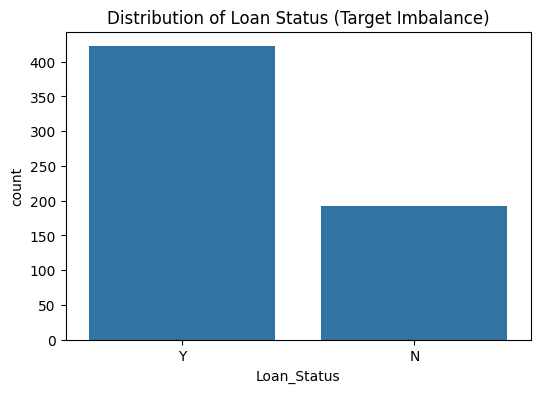

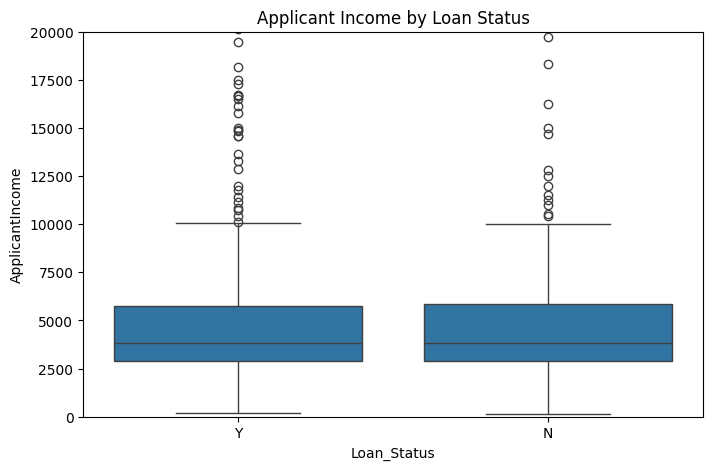

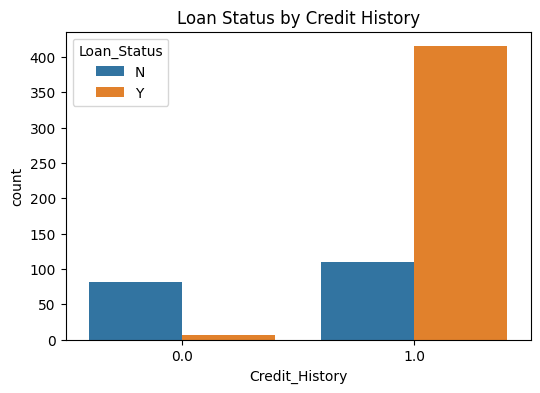

Confusion Matrix (Custom Threshold):
[[68 17]
 [13 25]]

Classification Report:
                  precision    recall  f1-score   support

        Safe (0)       0.84      0.80      0.82        85
Risk/Default (1)       0.60      0.66      0.62        38

        accuracy                           0.76       123
       macro avg       0.72      0.73      0.72       123
    weighted avg       0.76      0.76      0.76       123

ROC-AUC Score: 0.7486


/tmp/ipykernel_1872/3092134375.py:144: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances[indices][:10], y=X.columns[indices][:10], palette='viridis')


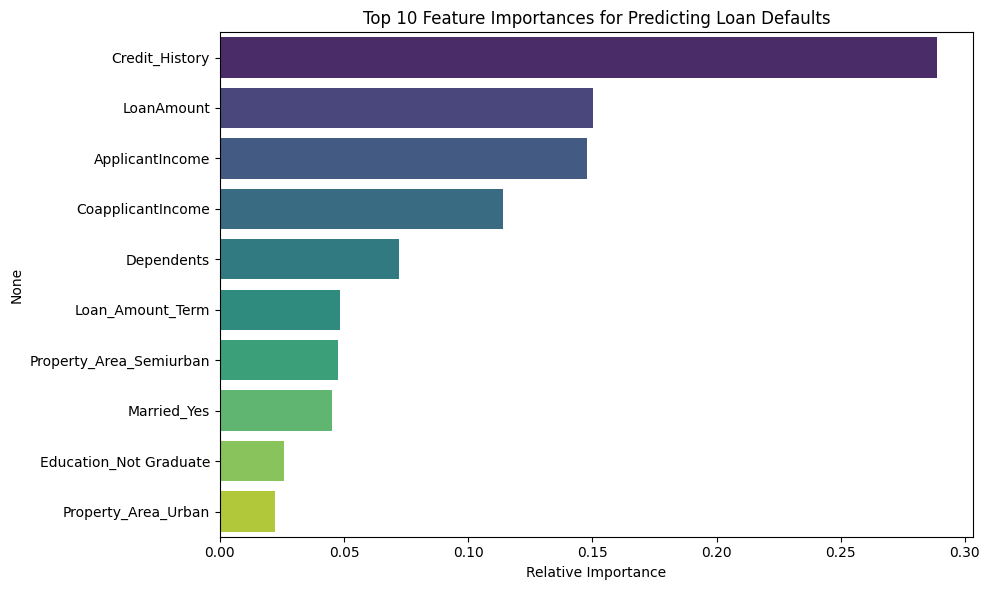

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, precision_recall_curve


from imblearn.over_sampling import SMOTE


df = pd.read_csv('/content/loan_data_set.csv')


df.drop('Loan_ID', axis=1, inplace=True)

for col in ['Gender', 'Married', 'Dependents', 'Self_Employed', 'Credit_History']:
    df[col] = df[col].fillna(df[col].mode()[0])


df['LoanAmount'] = df['LoanAmount'].fillna(df['LoanAmount'].median())
df['Loan_Amount_Term'] = df['Loan_Amount_Term'].fillna(df['Loan_Amount_Term'].mode()[0])



plt.figure(figsize=(6,4))
sns.countplot(x='Loan_Status', data=df)
plt.title('Distribution of Loan Status (Target Imbalance)')
plt.show()

plt.figure(figsize=(8,5))
sns.boxplot(x='Loan_Status', y='ApplicantIncome', data=df)
plt.title('Applicant Income by Loan Status')

plt.ylim(0, 20000)
plt.show()

plt.figure(figsize=(6,4))
sns.countplot(x='Credit_History', hue='Loan_Status', data=df)
plt.title('Loan Status by Credit History')
plt.show()



df['Target_Default'] = df['Loan_Status'].map({'N': 1, 'Y': 0})
df.drop('Loan_Status', axis=1, inplace=True)


df['Dependents'] = df['Dependents'].replace('3+', 3).astype(int)


cat_cols = ['Gender', 'Married', 'Education', 'Self_Employed', 'Property_Area']
df = pd.get_dummies(df, columns=cat_cols, drop_first=True)


X = df.drop('Target_Default', axis=1)
y = df['Target_Default']


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)



rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    class_weight='balanced',
    random_state=42
)
rf_model.fit(X_train_resampled, y_train_resampled)


y_probs = rf_model.predict_proba(X_test_scaled)[:, 1]


custom_threshold = 0.45
y_pred_custom = (y_probs >= custom_threshold).astype(int)



print("Confusion Matrix (Custom Threshold):")
print(confusion_matrix(y_test, y_pred_custom))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_custom, target_names=['Safe (0)', 'Risk/Default (1)']))

print(f"ROC-AUC Score: {roc_auc_score(y_test, y_probs):.4f}")



importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10, 6))

sns.barplot(x=importances[indices][:10], y=X.columns[indices][:10], palette='viridis')
plt.title('Top 10 Feature Importances for Predicting Loan Defaults')
plt.xlabel('Relative Importance')
plt.tight_layout()
plt.show()